In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [50]:
df = pd.read_csv("/content/loan_default.csv")
print(df.shape); df.info(); df.head(10)

(1012, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   object 
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   object 
 12  marital_status     1012 non-null   object 
 13  education          951 non-null    object 
 14  loan_purpose       1012 non-null   object 
 15  city_tier          1012 non-null   object 
 16  previous_defa

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


#Answer 1:
1. Number of Rows = 1012
2. Number of Columns = 18
3. Number of Categorical Columns = 7
4. Number of Numerical Columns = 11



In [51]:
df.describe()

,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,previous_defaults
count,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000
mean,42.669960,54157.542490,246006.705534,651.821146,9.994763,0.368216,0.996047,1.936759,8107.384951,9.325702,0.254941
std,13.986137,21295.031417,116654.104628,79.549937,7.718507,0.154261,0.979505,1.390213,6095.294697,1.424837,0.499481
min,-52.000000,-74577.000000,20000.000000,411.000000,0.000000,0.020000,0.000000,0.000000,0.000000,6.000000,0.000000
25%,32.000000,40859.000000,169464.500000,596.750000,3.875000,0.263000,0.000000,1.000000,3086.785000,8.370000,0.000000
50%,43.000000,53837.500000,242872.000000,651.500000,7.900000,0.371000,1.000000,2.000000,7747.690000,9.270000,0.000000
75%,54.000000,68032.750000,324349.500000,705.000000,14.525000,0.475250,2.000000,3.000000,12158.522500,10.252500,0.000000
max,64.000000,111578.000000,667635.000000,900.000000,33.600000,0.895000,4.000000,4.000000,34342.240000,14.880000,3.000000


In [52]:
print(df.value_counts("customer_id"))
df.value_counts("employment_type")

customer_id
CUST00050    2
CUST00453    2
CUST00143    2
CUST00447    2
CUST00243    2
            ..
CUST00342    1
CUST00343    1
CUST00344    1
CUST00345    1
CUST00330    1
Name: count, Length: 1000, dtype: int64


,count
employment_type,
Salaried,463
Self-employed,220
Business,186
Contract,143


In [53]:
cat_cols = df.select_dtypes(include=['object','category']).columns
for col in cat_cols:
  print("\n")
  print(40*"=",end="\n")
  print(df.value_counts(col))



customer_id
CUST00050    2
CUST00453    2
CUST00143    2
CUST00447    2
CUST00243    2
            ..
CUST00342    1
CUST00343    1
CUST00344    1
CUST00345    1
CUST00330    1
Name: count, Length: 1000, dtype: int64


employment_type
Salaried         463
Self-employed    220
Business         186
Contract         143
Name: count, dtype: int64


marital_status
Married     517
Single      409
Divorced     86
Name: count, dtype: int64


education
Undergraduate    377
Graduate         276
High School      183
Postgraduate     115
Name: count, dtype: int64


loan_purpose
Home         340
Personal     270
Business     247
Education    155
Name: count, dtype: int64


city_tier
Tier 1    416
Tier 2    350
Tier 3    246
Name: count, dtype: int64


loan_default
No     825
Yes    187
Name: count, dtype: int64


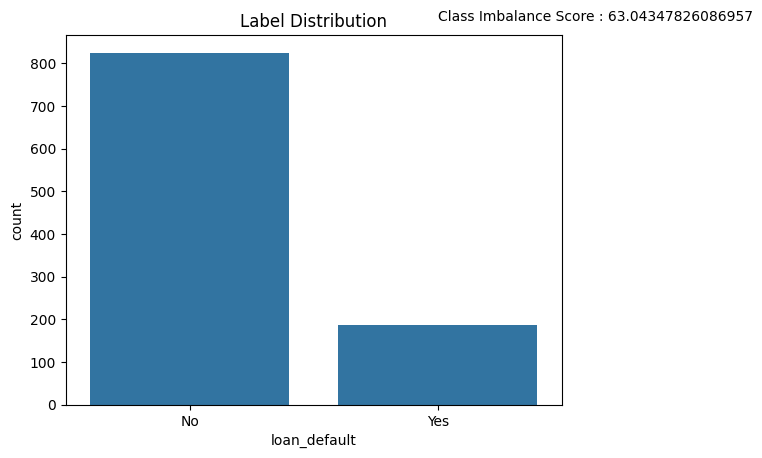

In [54]:
pos, neg = df.value_counts(['loan_default'])
countplot = sns.countplot(data=df, x='loan_default')
class_imbalance_score = (np.abs(pos - neg) / len(df)) * 100
plt.text(1, 900, f"Class Imbalance Score : {class_imbalance_score}")
plt.title("Label Distribution")

plt.show()

#Question 2:
###Is the target balanced, or are there far more Yes than No (or the reverse)? Why might this matter?
#Answer 2:
###No, the target labels are imbalanced, with far more "No" labels than "Yes" labels.
###This matters because machine learning models learn patterns from the training data. Since there are fewer examples of the "Yes" class, the model may become biased toward predicting the majority class ("No") more often. As a result, the model may achieve high overall accuracy while performing poorly at identifying the minority class ("Yes"), leading to misleading performance evaluation.

In [55]:
df.isnull().sum()

,0
customer_id,0
age,0
income,0
loan_amount,0
credit_score,0
employment_years,0
debt_to_income,0
existing_loans,0
dependents,0
bank_balance,0


In [56]:
edu_mode = df['education'].mode()[0]
df['education'] = df['education'].fillna(edu_mode)

In [57]:
df.isna().sum().sum()

np.int64(0)

In [58]:
df.duplicated().sum()

np.int64(11)

In [59]:
df.drop_duplicates(inplace=True)

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1001.0,42.677323,13.991454,-52.00,32.000,43.000,54.000,64.000
income,1001.0,54144.880120,21349.729312,-74577.00,40829.000,53848.000,68028.000,111578.000
loan_amount,1001.0,245843.510490,116880.587463,20000.00,169223.000,243066.000,323898.000,667635.000
credit_score,1001.0,651.578422,79.514301,411.00,596.000,651.000,704.000,900.000
employment_years,1001.0,10.010589,7.724730,0.00,3.900,7.900,14.600,33.600
debt_to_income,1001.0,0.368050,0.154014,0.02,0.263,0.371,0.475,0.895
existing_loans,1001.0,1.000999,0.982344,0.00,0.000,1.000,2.000,4.000
dependents,1001.0,1.937063,1.389617,0.00,1.000,2.000,3.000,4.000
bank_balance,1001.0,8108.234845,6092.209337,0.00,3089.620,7752.750,12143.440,34342.240
interest_rate,1001.0,9.331369,1.424047,6.00,8.380,9.280,10.260,14.880


In [62]:
df[(df['age'] < 0) | (df['income'] < 0)]

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
16,CUST00088,58,-29071.0,241087.0,724.0,5.3,0.382,0,2,90.06,8.47,Contract,Single,Undergraduate,Business,Tier 2,0,Yes
60,CUST00792,28,-42992.0,104027.0,614.0,1.8,0.020,0,2,0.00,9.60,Self-employed,Married,Graduate,Home,Tier 2,0,No
108,CUST00791,-35,61573.0,220100.0,689.0,8.6,0.378,1,4,11405.14,8.35,Salaried,Single,Graduate,Personal,Tier 3,1,Yes
166,CUST00377,32,-61524.0,122956.0,547.0,5.1,0.114,0,1,13164.48,10.26,Business,Married,Undergraduate,Education,Tier 3,0,Yes
237,CUST00050,-22,49113.0,192919.0,784.0,0.4,0.676,2,0,0.00,8.85,Self-employed,Single,Undergraduate,Education,Tier 1,1,No
331,CUST00320,23,-62841.0,41908.0,706.0,0.6,0.061,0,4,8563.76,8.68,Self-employed,Married,Undergraduate,Personal,Tier 1,0,No
461,CUST00713,-46,59189.0,103782.0,693.0,6.8,0.268,0,2,8766.70,8.19,Business,Single,Undergraduate,Home,Tier 2,0,No
510,CUST00339,26,-74577.0,277866.0,732.0,0.9,0.244,1,2,2516.75,8.96,Self-employed,Single,Undergraduate,Business,Tier 1,0,Yes
583,CUST00943,-52,71028.0,221711.0,635.0,6.9,0.285,0,1,12315.58,8.87,Business,Married,Undergraduate,Education,Tier 1,0,No
895,CUST00286,-39,41597.0,461144.0,668.0,6.6,0.185,2,2,13614.27,9.49,Business,Married,Graduate,Personal,Tier 3,0,Yes


In [63]:
df.loc[df['age'] < 0, 'age'] *= -1
df.loc[df['income'] < 0, 'income'] *= -1

In [64]:
df[(df['age'] < 0) | (df['income'] < 0)].count().sum()

np.int64(0)

In [65]:
print(f"Age Range : {df['age'].min()} to {df['age'].max()}")

Age Range : 21 to 64


##Question 3:
Which columns had missing values, and what did you do about them? Why did you choose that method.

###Answer 3:
Education column had 61 missing values, as the Education column has categorical data, I replaced the missing (NA) values with the **MODE** of Education Vector using `df["education"].fillna(edu_mode)`
I choosed this method because Education is a **categorical feature** and its missing in about 61 rows which has **significant statistical power**, so i should not drop those 61 rows.

Also I observed `age` and `income` columns had negative values therefore I inverted there sign as its most probably a mistake.

Also I verified that Age lies within correct Range `Age Range : 21 to 64`


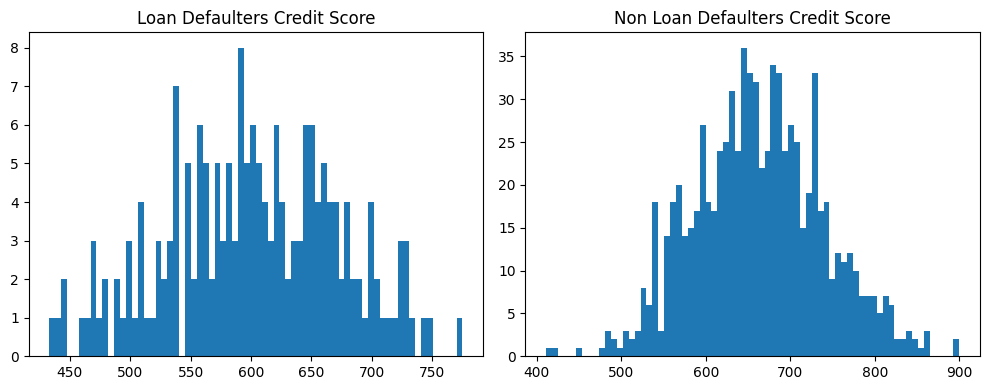

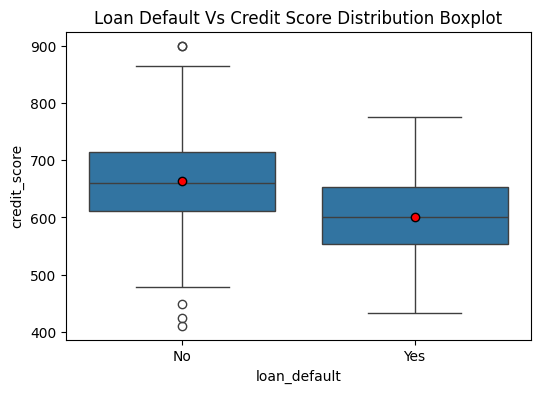

In [66]:
defaulters_credit_score = df.loc[df["loan_default"] == "Yes", "credit_score"]
non_defaulters_credit_score = df.loc[df["loan_default"] == "No", "credit_score"]

bin_size = 70

fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].hist(defaulters_credit_score, bins=bin_size)
ax[0].set_title("Loan Defaulters Credit Score")

ax[1].hist(non_defaulters_credit_score, bins=bin_size)
ax[1].set_title("Non Loan Defaulters Credit Score")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(data=df, x = 'loan_default', y = 'credit_score', showmeans=True,
    meanprops={
        'marker':'o',
        'markerfacecolor':'red',
        'markeredgecolor':'black'
    })
plt.title("Loan Default Vs Credit Score Distribution Boxplot")
plt.show()

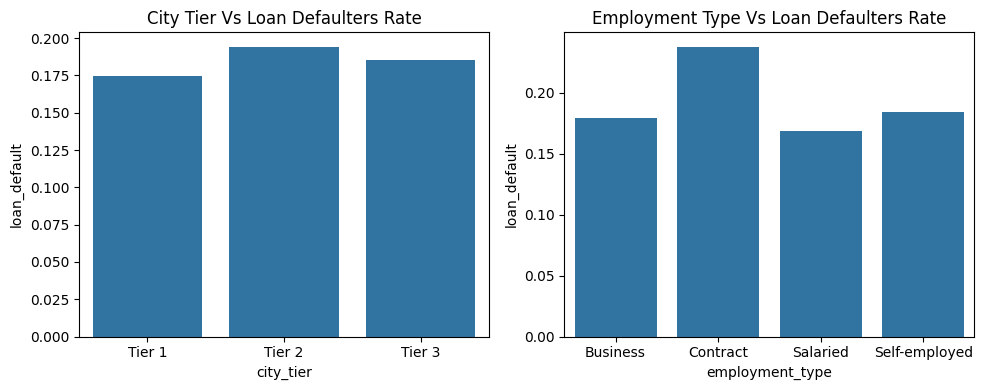

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

group_city_tier = df.groupby("city_tier")['loan_default'].apply(lambda x: (x == "Yes").mean()).reset_index()
sns.barplot(data=group_city_tier, x="city_tier", y="loan_default", ax=ax[0])
ax[0].set_title("City Tier Vs Loan Defaulters Rate")

group_emp_type = df.groupby("employment_type")['loan_default'].apply(lambda x: (x == "Yes").mean()).reset_index()
sns.barplot(data=group_emp_type, x="employment_type", y="loan_default", ax=ax[1])
ax[1].set_title("Employment Type Vs Loan Defaulters Rate")

plt.tight_layout()
plt.show()

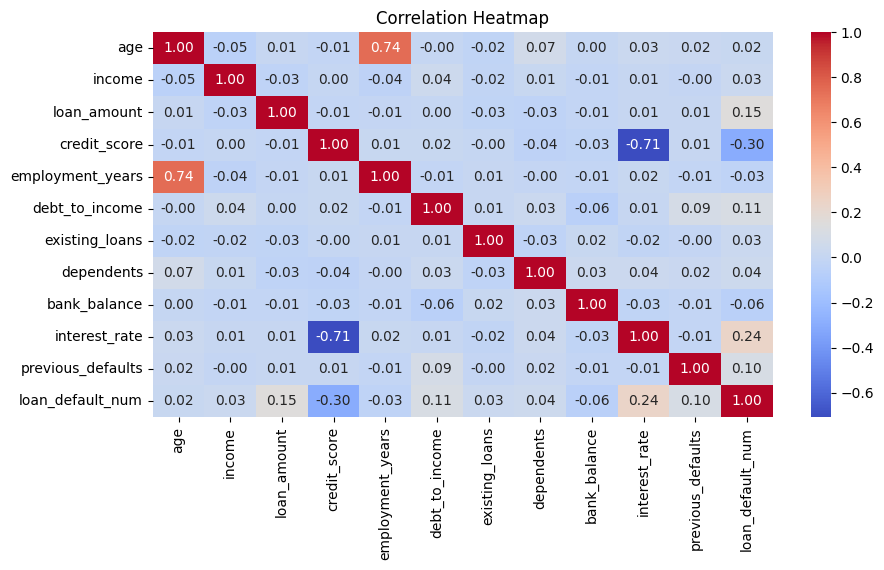

In [68]:
df["loan_default_num"] = (df["loan_default"]=='Yes').astype(int)
num_df = df.select_dtypes(include='number')
corr_matrix = num_df.corr()

plt.figure(figsize=(10,5))
sns.heatmap(data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

##Question 4:
Which two features appear to separate defaulters from non-defaulters best?


#Answer 4:
The two features that appear to separate defaulters from non-defaulters best are credit_score and interest_rate.

Credit Score shows the clearest separation. The boxplot indicates that customers who defaulted generally have lower credit scores than customers who did not default. This is also supported by the correlation heatmap, where credit_score has the strongest correlation with loan_default (-0.30).

Interest Rate appears to be the second most important feature. The correlation heatmap shows a positive correlation (0.24) with loan_default, suggesting that customers charged higher interest rates are more likely to default.

In [69]:
df = df.drop(columns=['customer_id', 'loan_default'])
df = pd.get_dummies(data=df, drop_first=True)
X = df.drop('loan_default_num', axis=1)
y = df['loan_default_num']

In [70]:
print(X.shape, y.shape)

(1001, 24) (1001,)


##Question 5:
Why can't a Decision Tree in scikit-learn use text columns directly?
#Answer 5:
Scikit-learn Decision Trees require numerical input data. Text values cannot be used directly because the tree's splitting rules are based on numerical comparisons. Therefore, categorical text columns must be encoded into numbers before model training.

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train,  y_test = train_test_split(X, y, train_size=0.8, stratify=y, random_state=42)

In [72]:
print(f"X_train : {X_train.shape}, y_train : {y_train.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape}")

X_train : (800, 24), y_train : (800,)
X_test : (201, 24), y_test : (201,)


##Question 6:
Why do we keep a test set aside and never train on it?

#Answer 6:
After the model training and hyperparameter tuning we need test dataset to evaluate our final ml model on its generizability and to simulate how it will perform in real cases after deployment. The test data should be used only once and model should not be aware or have seen it before its testing.

In [73]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [74]:
train_prediction = dt.predict(X_train)
test_prediction = dt.predict(X_test)

In [75]:
from sklearn.metrics import accuracy_score
train_accuracy = accuracy_score(y_train, train_prediction)
test_accuracy = accuracy_score(y_test, test_prediction)

print("Accuracy on Train Dataset : ", train_accuracy)
print("Accuracy on Test Dataset : ", test_accuracy)

Accuracy on Train Dataset :  1.0
Accuracy on Test Dataset :  0.7661691542288557


In [76]:
print(dt.score(X_train, y_train), dt.score(X_test, y_test))

1.0 0.7661691542288557


##Question 7:
Is there a big gap between training and test accuracy? What does this suggest (overfitting or not)?
#Answer 7:
Yes, Training and Test accuracy are widely apart which is about 0.24 units away. As the training accuracy is near perfect (1) while test accuracy is only 0.7661, we can conclude that the model has memorised and learned noise in train dataset and have poor generizability for the test set. Hence, the model is **overfitting**

In [77]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
print("Confusion Matrix : ", confusion_matrix(y_test, test_prediction))
print("Classification Report : ", classification_report(y_test, test_prediction))
print("ROC AUC Score : ", roc_auc_score(y_test, test_prediction))

Confusion Matrix :  [[141  23]
 [ 24  13]]
Classification Report :                precision    recall  f1-score   support

           0       0.85      0.86      0.86       164
           1       0.36      0.35      0.36        37

    accuracy                           0.77       201
   macro avg       0.61      0.61      0.61       201
weighted avg       0.76      0.77      0.76       201

ROC AUC Score :  0.6055537244561634


##Question 8:
In loan default prediction, which is worse: approving a loan that defaults, or rejecting a good customer? Which metric does this make most important?

#Answer 8:
Approving a loan that default is more dangerous in loan default prediction. For this prediction, we need to reduce **False Negatives**, therefore **Recall** is the most important metric here.

In [78]:
max_depth = [3, 5, 7, 10]

for i in max_depth:
  dt_new = DecisionTreeClassifier(max_depth=i, random_state=42)
  dt_new.fit(X_train, y_train)

  new_train_predict = dt_new.predict(X_train)
  new_test_predict = dt_new.predict(X_test)

  print(f"Accuracy on Train Set with max_depth as {i} : ", accuracy_score(y_train, new_train_predict), end="\n")
  print(f"Accuracy on Test Set with max_depth as {i} : ", accuracy_score(y_test, new_test_predict), end="\n")


Accuracy on Train Set with max_depth as 3 :  0.84375
Accuracy on Test Set with max_depth as 3 :  0.8208955223880597
Accuracy on Train Set with max_depth as 5 :  0.86625
Accuracy on Test Set with max_depth as 5 :  0.8258706467661692
Accuracy on Train Set with max_depth as 7 :  0.905
Accuracy on Test Set with max_depth as 7 :  0.8159203980099502
Accuracy on Train Set with max_depth as 10 :  0.96625
Accuracy on Test Set with max_depth as 10 :  0.7810945273631841


In [79]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth':[3, 5, 7, 10],
    'min_samples_leaf':[3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    'criterion':['gini', 'entropy']
}

grid = GridSearchCV(estimator=dt, param_grid=param_grid, scoring="accuracy", cv=5, n_jobs=-1)

grid.fit(X_train, y_train)

print("Best Parameters : ", grid.best_params_)
print("Best Score : ", grid.best_score_)

best_dt = grid.best_estimator_

predict_new_test = best_dt.predict(X_test)

print("Accuracy of best model on Test Dataset : ", accuracy_score(y_test, predict_new_test))
print("Classification Report of best model on Test Dataset : ", classification_report(y_test, predict_new_test))

Best Parameters :  {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 9}
Best Score :  0.8275
Accuracy of best model on Test Dataset :  0.8159203980099502
Classification Report of best model on Test Dataset :                precision    recall  f1-score   support

           0       0.82      0.99      0.90       164
           1       0.50      0.05      0.10        37

    accuracy                           0.82       201
   macro avg       0.66      0.52      0.50       201
weighted avg       0.76      0.82      0.75       201



##Question 9:
Which max_depth gave the best test result? How did tuning change your scores compared with Step 7?
#Answer 9:
Max Depth of 3 gave the best test result.
Tuning the Hyperparameters reduced overfitting and made the test and train accuracy to come more closer to the point just before they started diverging.

In [80]:

num_columns = X.select_dtypes(include='number').columns
print(num_columns)

Index(['age', 'income', 'loan_amount', 'credit_score', 'employment_years',
       'debt_to_income', 'existing_loans', 'dependents', 'bank_balance',
       'interest_rate', 'previous_defaults'],
      dtype='object')


In [81]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_columns] = std_scaler.fit_transform(X_train[num_columns])
X_test_scaled[num_columns] = std_scaler.transform(X_test[num_columns])

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_train_scaled_df.head()


,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,...,marital_status_Married,marital_status_Single,education_High School,education_Postgraduate,education_Undergraduate,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,city_tier_Tier 2,city_tier_Tier 3
163,-0.387208,-0.841528,0.851493,0.924444,0.212110,0.222382,2.033314,-1.384622,0.856024,-2.092054,...,True,False,False,False,False,False,False,False,False,False
544,0.944614,0.668983,0.247406,0.430741,0.945576,-0.455958,-1.016657,-0.668129,-0.118495,0.056433,...,False,True,True,False,False,False,True,False,True,False
680,1.493011,-1.022912,-0.064277,-0.506030,-0.096718,1.650127,-1.016657,0.764856,-1.364192,-0.834058,...,True,False,False,False,True,False,True,False,True,False
775,0.239532,1.246525,-0.757418,-0.670598,0.945576,1.540300,-1.016657,0.048363,-1.317440,0.487544,...,True,False,False,True,False,False,False,True,False,True
448,-0.230523,0.713688,-0.927607,-1.620029,-0.624298,0.448496,-1.016657,-0.668129,1.344069,0.317927,...,False,False,False,False,True,False,False,False,False,True


In [82]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42)

lr.fit(X_train_scaled, y_train)

base_train_prediction = lr.predict(X_train_scaled)
base_test_prediction = lr.predict(X_test_scaled)

print("Base Logistic Regression Model Accuracy for Train Dataset : ", accuracy_score(y_train, base_train_prediction))
print("Base Logistic Regression Model Accuracy for Test Dataset : ", accuracy_score(y_test, base_test_prediction))

Base Logistic Regression Model Accuracy for Train Dataset :  0.8375
Base Logistic Regression Model Accuracy for Test Dataset :  0.8308457711442786


In [83]:
from sklearn.metrics import recall_score, f1_score, roc_auc_score

models = {"Logistic Regression" : lr, "Decision Tree Classifier" : dt, "Tuned Decision Tree Classifier": best_dt}
metrics = {"Accuracy": accuracy_score, "Recall": recall_score, "F1 Score": f1_score, "AUC ROC Score": roc_auc_score}

table = {"Accuracy": [], "Recall": [], "F1 Score": [], "AUC ROC Score": []}

for metric in metrics:
  for model in models:
    if(model == "Logistic Regression"):
      table[metric].append(metrics[metric](y_test, models[model].predict(X_test_scaled)))
    else:
      table[metric].append(metrics[metric](y_test, models[model].predict(X_test)))

model_metric_table = pd.DataFrame(table, index=list(models.keys()))


In [84]:
model_metric_table.head()

,Accuracy,Recall,F1 Score,AUC ROC Score
Logistic Regression,0.830846,0.216216,0.320000,0.592864
Decision Tree Classifier,0.766169,0.351351,0.356164,0.605554
Tuned Decision Tree Classifier,0.815920,0.054054,0.097561,0.520929


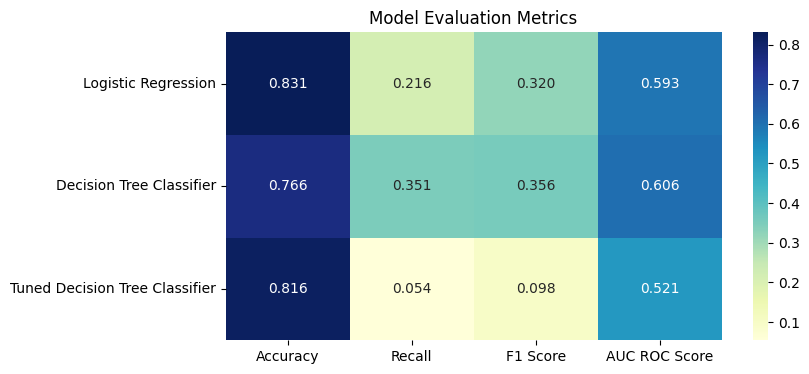

In [85]:
plt.figure(figsize=(8, 4))
sns.heatmap(data=model_metric_table, annot=True, cmap="YlGnBu",
    fmt=".3f")

plt.title("Model Evaluation Metrics")
plt.show()

##Question 10:
Which model would you recommend to the bank and why?
#Answer 10:
I would recommend Decision Tree Classifier to the bank as it clearly has higher Recall which is an important factor to have less False Negatives. Also it is interpretable than logistic regression.




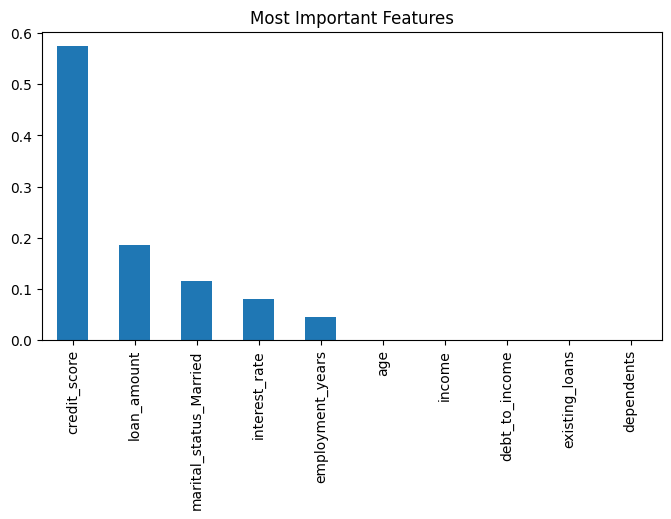

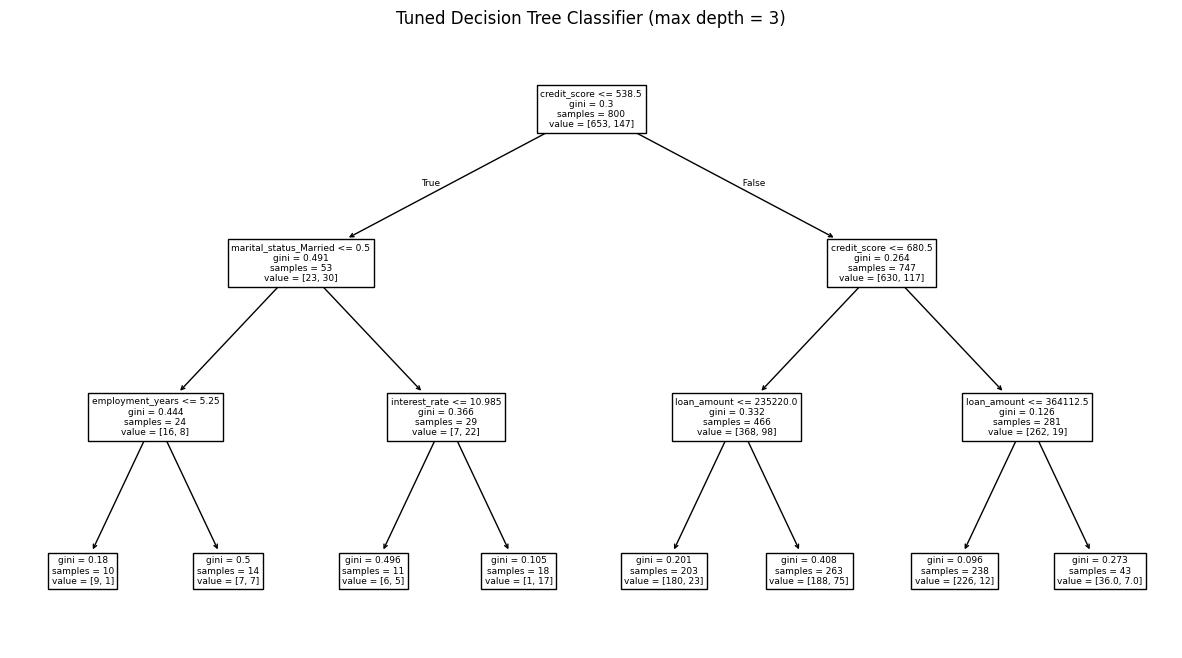

In [86]:
from sklearn.tree import plot_tree

plt.figure(figsize = (8, 4))

pd.Series(best_dt.feature_importances_, index=X.columns).nlargest(10).plot(kind="bar")

plt.title("Most Important Features")

plt.show()


plt.figure(figsize = (15, 8))

plot_tree(best_dt, max_depth = 3, feature_names=X.columns)

plt.title("Tuned Decision Tree Classifier (max depth = 3)")

plt.show()

#Question 11:
 List the top five features. Do they match what you saw in Step 4? Explain two decision rules from the tree in plain English.

##Answer 11 :
The top five features observed are credit score, loan amount, martial status, interest rate and employment years. The features credit score and interest rate matches the most correlating features from step 4.

The Descision Tree makes first split on Credit Score, if the credit score is less or equal to 538.5, go to left subtree else go to right subtree.
If the credit score is less than 538.5 and the person is married then check on interest rate.


#Question 12:
What does the model do well, what are its limitations, and what one thing would you do to improve it (e.g., more data, a Random Forest, different features)?
#Answer 12:
The model correctly identifies important features within the dataset and is able to correctly classify many test examples.
The model has few limitaions:
1. **Less Data** :It doesnt have enough training examples to prevent it from overfitting early on and the dataset is imablanced with far more negative than positive labels. Its able to detect important features but due to less training data the model cannot see the broader pattern.

2. **Less Feature Diversity**: There are various number of features to predict the default but model is highly variant on top 3 like credit score, loan amount, martial status.
To solve this the ensemble method like Random Forest should be incorporated to have improvement in accuray, recall and overall metrics. Random forest randomly chooses various features to split on therefore increasing the diversity of models (trees). It helps them to have overall estimate about the different feature combinations and reduce variance to only few. It helps to boost predictability and generizability.

Therefore, I will first use Decision Trees (Bagging) and observe the slight improvements in generizability, after that i will consider feature engineering and use more data.